# 67 — Pinatubo Historical earthquake COUNTS

Run step 60 first. This notebook reads unpacked source folders using `flovopy.legacy.bob`; Pinatubo paths and interpretation remain here. Outputs go to the configured external `FAIR/BOB` tree. Source data are unchanged.


## Review of the supplied saved execution

Saved run: 5,189 rows; three parser errors, one invalid timestamp, four duplicate-timestamp rows. Errors include OUT OF ORDER text and month SEO. More subtly, both CAB versions contain two syntactically valid 13 July 1919 labels (06:30 and 08:30), four records in total. These are flagged, retained and excluded from expected-period coverage; no replacement date is guessed. CAB_CNT and CAB_HR remain alternative versions.

This describes the supplied version, not a new execution. Revised code cells have been cleared so stale results cannot be mistaken for current outputs. The original executed notebook is backed up.


## Data meaning, clock policy and unresolved questions

CAB_CNT and CAB_HR are overlapping alternatives and must remain distinct. PIE_CNT has its own provenance/time convention. These historical counts are neither waveform-file counts nor a complete modern event catalogue. Zero counts are valid; missing sentinels and malformed dates remain flagged.

Do not sum source alternatives when making an earthquake-rate plot. A larger row count can reflect duplicate versions rather than additional observations. Review negative values and the known malformed CAB dates before selecting a preferred series.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, re
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
# Support launching Jupyter from either the repository or 10_conversion.
HERE = Path.cwd().resolve()
CONVERSION = HERE if (HERE / 'pinatubo_steps').is_dir() else HERE / '10_conversion'
if not (CONVERSION / 'pinatubo_steps').is_dir():
    raise RuntimeError('Launch Jupyter from the repository root or 10_conversion.')
if str(CONVERSION) not in sys.path: sys.path.insert(0, str(CONVERSION))
from pinatubo_steps.config import pipeline_paths, load_conversion_config
CONFIG_FILE = os.environ.get('PINATUBO_CONVERSION_CONFIG')  # None selects shared default
PATHS = pipeline_paths(config_file=CONFIG_FILE)
CONFIG = load_conversion_config(CONFIG_FILE)
BOB_CONFIG = CONFIG.get('legacy_bob', {})
BOB_ROOT = Path(PATHS['LEGACY_TOP']) / 'BOB'
BOB_OUTPUT = Path(PATHS['FAIR_TOP']) / 'BOB'
NOTEBOOK_NAME = '67_counts.ipynb'
OVERWRITE = True  # Set True only to deliberately replace this notebook's derived products.
print('Inputs:', BOB_ROOT, '\nOutputs:', BOB_OUTPUT)


Inputs: /Users/thompsong/Library/CloudStorage/Box-Box/thompsong/DATA/pinatubo1991/LEGACY/BOB 
Outputs: /Users/thompsong/work/Pinatubo1991Processing/converted/FAIR/BOB


## Reviewed exports, provenance and diagnostics

The definitions below add QC flags without correcting source times or values. Expected dates default to 1991, with 1992 allowed for SSAM/DATA. Override `legacy_bob.<product>.expected_dates.start` / `end_exclusive` only with evidence. Off-period and invalid labels remain in the complete records export and `date_review.csv`, but do not stretch reviewed coverage or plots. All-date coverage is separately preserved.

Exports include field statistics, duplicate records, source-role candidates, daily coverage, code/config provenance and a completion marker. Tabular products are staged before replacing derived outputs; a failed export is not marked complete. `OVERWRITE=False` protects existing exports. Because previous outputs already exist, deliberately set it True to regenerate them after reviewing these changes. No LEGACY measurements are modified. Figures are diagnostic outputs that may be regenerated; old PNGs should be checked against `plot_manifest.csv`.

The helper is embedded here to keep the notebook self-contained. Figures show daily availability by original source series and unique recorded labels per day, plus value panels. All series are plotted unless a visible limit is requested; auxiliary copies are flagged rather than silently merged or removed.


In [2]:
from flovopy.legacy.bob import (read_rsam, read_rsam_events, read_ssam, read_tilt,
    read_rain, read_mudflow, read_cospec, read_counts, read_radio_maps,plot_series,plot_ssam)
import tempfile, importlib.metadata

QC_SCHEMA_VERSION = 2

def product_source(product, default):
    relative=Path(BOB_CONFIG.get(product,{}).get('source_subdir',default))
    if relative.is_absolute() or '..' in relative.parts:
        raise ValueError('source_subdir must be relative to LEGACY/BOB')
    source=(BOB_ROOT/relative).resolve()
    if not source.is_relative_to(BOB_ROOT.resolve()) or not source.is_dir():raise FileNotFoundError(source)
    archives=list(source.rglob('*.[zZ][iI][pP]'))
    if archives:raise RuntimeError(f'{len(archives)} active ZIP(s); resolve step 60 before reading {source}')
    return source

def value_columns(frame):
    return [c for c in frame if re.fullmatch(r'value_\d+',c)]

def quality_frame(dataset, product):
    """Add review flags without changing recorded labels or measurement values."""
    frame=dataset.data.copy()
    bounds=BOB_CONFIG.get(product,{}).get('expected_dates',{})
    low=pd.Timestamp(bounds.get('start','1991-01-01'))
    high=pd.Timestamp(bounds.get('end_exclusive','1993-01-01' if product in ('ssam','ssam_data') else '1992-01-01'))
    if high<=low:raise ValueError('expected_dates.end_exclusive must exceed start')
    stamps=pd.to_datetime(frame.get('recorded_time',pd.Series(index=frame.index,dtype='datetime64[ns]')),errors='coerce')
    frame['qc_invalid_time']=stamps.isna()
    frame['qc_outside_expected_dates']=stamps.notna() & ((stamps<low)|(stamps>=high))
    # Auxiliary names are review candidates, not grounds for automatic deletion/merging.
    frame['qc_auxiliary_source']=frame.get('series',pd.Series('',index=frame.index)).astype(str).str.contains(r'(?i)(?:^|/)(?:TEMP|TEST[^/]*)(?:/|$)',regex=True)
    columns=value_columns(frame)
    frame['qc_has_value']=np.isfinite(frame[columns]).any(axis=1) if columns else False
    frame['qc_use_for_coverage']=frame.qc_has_value & ~frame.qc_invalid_time & ~frame.qc_outside_expected_dates
    return frame,dict(start=str(low),end_exclusive=str(high))

def export_product(dataset, product, notes):
    """Write reviewed coverage alongside complete raw-value records; commit marker last."""
    target=BOB_OUTPUT/product
    if not OVERWRITE and any((target/n).exists() for n in [product+'_records.csv','coverage.csv','export_status.json']):
        raise FileExistsError(f'{target}: existing derived products; review OVERWRITE before rerunning')
    frame,bounds=quality_frame(dataset,product)
    dataset.data=frame  # Only new QC columns; original labels/raw values are preserved.
    now=datetime.now(timezone.utc).isoformat()
    run_id=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    descriptions=BOB_ROOT/'STATIONS.TXT';context={}
    if descriptions.exists():
        blob=descriptions.read_bytes();context=dict(path=str(descriptions),sha256=hashlib.sha256(blob).hexdigest(),text=blob.decode('cp1252',errors='replace'))
    provenance={}
    if 'CONVERSION' in globals():
        notebook=Path(CONVERSION)/NOTEBOOK_NAME
        if notebook.exists():provenance['notebook_sha256']=hashlib.sha256(notebook.read_bytes()).hexdigest()
    import flovopy
    provenance['flovopy_location']=str(Path(flovopy.__file__).resolve())
    for module_name in ['annual','tabular','spectral','common','model']:
        module=__import__('flovopy.legacy.bob.'+module_name,fromlist=['__file__'])
        provenance[module_name+'_sha256']=hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
    metadata=dict(dataset.metadata)
    metadata.update(pinatubo_notes=notes,conversion_config=CONFIG,source_context=context,
        time_policy='Recorded labels retained; no timezone or drift correction',
        qc_schema_version=QC_SCHEMA_VERSION,run_id=run_id,expected_dates=bounds,code_provenance=provenance)
    dataset.metadata=metadata
    raw_coverage=dataset.coverage()
    from flovopy.legacy.bob import BOBDataset
    reviewed=BOBDataset(frame.loc[~frame.qc_invalid_time & ~frame.qc_outside_expected_dates],metadata,dataset.errors)
    coverage=reviewed.coverage()
    if len(coverage):
        coverage['valid_days']=coverage.series.map(frame.loc[frame.qc_use_for_coverage].groupby('series').recorded_time.apply(lambda x:x.dt.floor('D').nunique())).fillna(0).astype(int)
    daily=frame.loc[frame.qc_use_for_coverage,['series','recorded_time']].copy()
    daily['recorded_date']=pd.to_datetime(daily.recorded_time).dt.floor('D')
    daily=daily.groupby(['series','recorded_date']).agg(records=('recorded_time','size'),unique_timestamps=('recorded_time','nunique')).reset_index()
    field_rows=[]
    for series,group in frame.groupby('series',sort=True):
        for column in value_columns(frame):
            valid=group.loc[~group.qc_invalid_time & ~group.qc_outside_expected_dates,column]
            finite=valid[np.isfinite(valid)]
            field_rows.append(dict(series=series,field=column,records=len(group),nonmissing_in_expected_dates=len(finite),
                zeros=int((finite==0).sum()),negative_values=int((finite<0).sum()),
                minimum=finite.min() if len(finite) else np.nan,maximum=finite.max() if len(finite) else np.nan))
    duplicate=frame.get('duplicate_timestamp',pd.Series(False,index=frame.index)).fillna(False).astype(bool)
    # Radio dates are snapshots, not duplicate events; they have no value columns.
    duplicate_count=int(duplicate.sum())
    invalid_count=int(frame.qc_invalid_time.sum());outside_count=int(frame.qc_outside_expected_dates.sum())
    review=dict(qc_schema_version=QC_SCHEMA_VERSION,run_id=run_id,generated_utc=now,product=product,rows=len(frame),
        parser_errors=len(dataset.errors),invalid_times=invalid_count,outside_expected_dates=outside_count,
        auxiliary_source_rows=int(frame.qc_auxiliary_source.sum()),duplicate_timestamp_rows=duplicate_count,
        ambiguous_timestamps=int(frame.loc[duplicate,['series','recorded_time']].drop_duplicates().shape[0]),
        expected_dates=bounds,status='review_required' if any([len(dataset.errors),invalid_count,outside_count,duplicate_count,int(frame.qc_auxiliary_source.sum())]) else 'no_automatic_flags',
        coverage_meaning='A finite nonsentinel value with valid recorded label inside the documented expected date bounds; not uptime.',notes=notes)
    target.parent.mkdir(parents=True,exist_ok=True)
    # Stage the complete tabular export before altering an existing product directory.
    with tempfile.TemporaryDirectory(prefix='.'+product+'_',dir=target.parent) as temporary:
        temp=Path(temporary)
        dataset.write(temp,prefix=product)
        coverage.to_csv(temp/'coverage.csv',index=False)
        raw_coverage.to_csv(temp/'coverage_all_recorded_dates.csv',index=False)
        daily.to_csv(temp/'daily_coverage.csv',index=False)
        pd.DataFrame(field_rows).to_csv(temp/'field_quality.csv',index=False)
        frame.loc[duplicate].to_csv(temp/'duplicate_records.csv',index=False)
        frame.loc[frame.qc_invalid_time|frame.qc_outside_expected_dates].to_csv(temp/'date_review.csv',index=False)
        source_roles=frame[['series','source_file','qc_auxiliary_source']].drop_duplicates()
        source_roles.to_csv(temp/'source_roles.csv',index=False)
        (temp/'review.json').write_text(json.dumps(review,indent=2,default=str)+'\n')
        (temp/'source_context.json').write_text(json.dumps(context,indent=2)+'\n')
        files=list(temp.iterdir())
        if not OVERWRITE and any((target/f.name).exists() for f in files+[temp/'export_status.json']):
            raise FileExistsError(f'{target}: outputs exist; set OVERWRITE=True only to replace derived products. LEGACY is unchanged.')
        target.mkdir(exist_ok=True)
        (target/'export_status.json').write_text(json.dumps(dict(complete=False,run_id=run_id))+'\n')
        for file in files:os.replace(file,target/file.name)
        (target/'export_status.json').write_text(json.dumps(dict(complete=True,qc_schema_version=QC_SCHEMA_VERSION,run_id=run_id,generated_utc=now))+'\n')
    display(coverage);display(dataset.errors.head(20))
    if outside_count:display(frame.loc[frame.qc_outside_expected_dates,['series','source_file','recorded_time','raw_line'] if 'raw_line' in frame else ['series','source_file','recorded_time']].head(20))
    print({k:v for k,v in review.items() if k!='notes'})
    return target

def plot_product(dataset, target, max_series=None):
    """Daily unique-label bars, daily availability by series, and explicit value panels."""
    import matplotlib.dates as mdates
    daily=pd.read_csv(target/'daily_coverage.csv',parse_dates=['recorded_date'])
    product=target.name
    if len(daily):
        counts=daily.groupby('recorded_date').unique_timestamps.sum()
        days=pd.date_range(counts.index.min(),counts.index.max(),freq='D')
        fig,ax=plt.subplots(figsize=(12,3))
        ax.bar(days,counts.reindex(days,fill_value=0),width=1,align='edge')
        ax.set(ylabel='Unique labels across source series',xlabel='Recorded calendar date',title=product+' — retained records (source versions remain separate)')
        fig.autofmt_xdate();fig.tight_layout();fig.savefig(target/'daily_records.png',dpi=180);plt.show();plt.close(fig)
        series=sorted(daily.series.unique())
        fig,ax=plt.subplots(figsize=(12,max(3,.3*len(series)+1.5)))
        for i,name in enumerate(series):
            dates=daily.loc[daily.series.eq(name),'recorded_date']
            ax.broken_barh([(mdates.date2num(t),1) for t in dates],(i-.35,.7),facecolors='C0')
        ax.set_yticks(range(len(series)),series);ax.invert_yaxis();ax.xaxis_date()
        locator=mdates.AutoDateLocator(minticks=3,maxticks=8)
        ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set(title=product+' — daily availability by original source series',xlabel='Recorded calendar date; gaps retained')
        ax.grid(axis='x',alpha=.2);fig.tight_layout();fig.savefig(target/'availability_by_series.png',dpi=180);plt.show();plt.close(fig)
    else:print('No measurement coverage to plot; inspect snapshot tables or review.json.')
    # Crop padded annual arrays to their usable times. Off-period dates remain in date_review.csv.
    columns=value_columns(dataset.data)
    expected=dataset.metadata.get('expected_fields')
    if expected is not None:columns=[c for c in columns if int(c.split('_')[1])<=expected]
    valid=dataset.data.loc[dataset.data.qc_use_for_coverage].copy()
    series=list(valid.get('series',pd.Series(dtype=str)).dropna().unique())
    chosen=series if max_series is None else series[:max_series]
    manifest=[]
    for name in series:
        if name not in chosen:
            manifest.append(dict(series=name,status='not_plotted_explicit_limit'));continue
        group=valid.loc[valid.series.eq(name)].sort_values('recorded_time',kind='stable')
        fig,axes=plt.subplots(len(columns),1,sharex=True,squeeze=False,figsize=(11,max(3,1.8*len(columns))))
        channel=str(name).split('/')[-1]
        meanings=dataset.metadata.get('channel_metadata',{}).get(channel,{})
        for ax,column in zip(axes[:,0],columns):
            ax.plot(group.recorded_time,group[column],'.',markersize=2)
            ax.set_ylabel(column+'\nsource units');ax.grid(alpha=.2)
        axes[-1,0].set_xlabel('Recorded calendar label; no clock correction')
        locator=mdates.AutoDateLocator(minticks=3,maxticks=7)
        axes[-1,0].xaxis.set_major_locator(locator);axes[-1,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        fig.suptitle(str(name)+' — '+meanings.get('observable','uncalibrated source values'))
        fig.tight_layout()
        safe=re.sub(r'[^A-Za-z0-9_.-]+','_',str(name))+'_'+hashlib.sha256(str(name).encode()).hexdigest()[:6]
        path=target/f'series_{safe}.png';fig.savefig(path,dpi=160);plt.show();plt.close(fig)
        manifest.append(dict(series=name,status='plotted',path=str(path)))
    pd.DataFrame(manifest,columns=['series','status','path']).to_csv(target/'plot_manifest.csv',index=False)


In [3]:
NOTES = 'CAB_CNT and CAB_HR are overlapping alternatives and must remain distinct. PIE_CNT has its own provenance/time convention. These historical counts are neither waveform-file counts nor a complete modern event catalogue. Zero counts are valid; missing sentinels and malformed dates remain flagged.\n\nDo not sum source alternatives when making an earthquake-rate plot. A larger row count can reflect duplicate versions rather than additional observations. Review negative values and the known malformed CAB dates before selecting a preferred series.'


## Read, export and inspect

Review the coverage and parser-error tables. Unexpected source folders, dates, sentinels or duplicate times require investigation before quantitative analysis. Error records are exported even when readable rows are available. Plots are diagnostics, not calibrated scientific results.


,series,records,nonmissing_records,first,last,unique_nonmissing_timestamps,valid_days
0,CAB_CNT.DAT,3365,2670,1991-06-16 10:30:00,1991-11-06 00:30:00,2669,142
1,CAB_HR.DAT,1782,1609,1991-06-16 10:30:00,1991-08-30 16:30:00,1608,74
2,PIE_CNT.DAT,37,34,1991-04-30 00:00:00,1991-06-04 00:00:00,34,34


,source_file,source_line,raw_line,reason
0,CAB_CNT.DAT,1627,21 AUG 91 21:30 OUT OF ORDER,expected_1_fields_found_3;invalid_numeric_toke...
1,CAB_CNT.DAT,2331,20 SEO 91 04:30 1.,invalid_datetime: 'SEO'
2,CAB_HR.DAT,1627,21 AUG 91 21:30 OUT OF ORDER,expected_1_fields_found_3;invalid_numeric_toke...


,series,source_file,recorded_time,raw_line
644,CAB_CNT.DAT,CAB_CNT.DAT,1919-07-13 06:30:00,13 JUL 19 06:30 3.
646,CAB_CNT.DAT,CAB_CNT.DAT,1919-07-13 08:30:00,13 JUL 19 08:30 3.
4012,CAB_HR.DAT,CAB_HR.DAT,1919-07-13 06:30:00,13 JUL 19 06:30 3.
4014,CAB_HR.DAT,CAB_HR.DAT,1919-07-13 08:30:00,13 JUL 19 08:30 3.


{'qc_schema_version': 2, 'run_id': '20261112T170413239472Z', 'generated_utc': '2026-11-12T17:04:13.239462+00:00', 'product': 'counts', 'rows': 5189, 'parser_errors': 3, 'invalid_times': 1, 'outside_expected_dates': 4, 'auxiliary_source_rows': 0, 'duplicate_timestamp_rows': 4, 'ambiguous_timestamps': 2, 'expected_dates': {'start': '1991-01-01 00:00:00', 'end_exclusive': '1992-01-01 00:00:00'}, 'status': 'review_required', 'coverage_meaning': 'A finite nonsentinel value with valid recorded label inside the documented expected date bounds; not uptime.'}


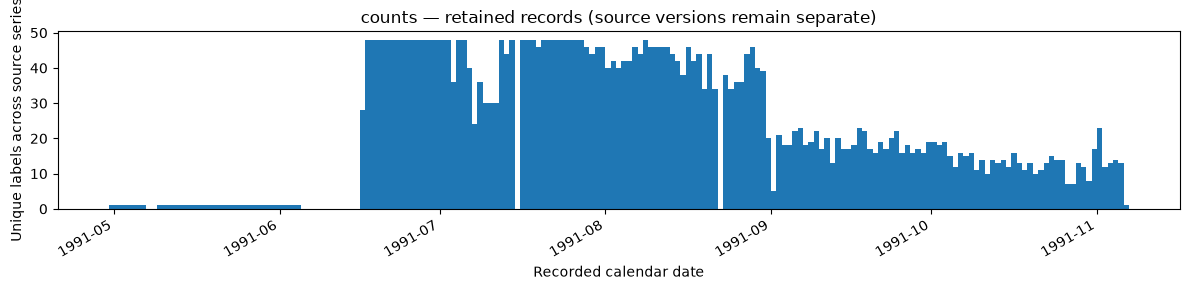

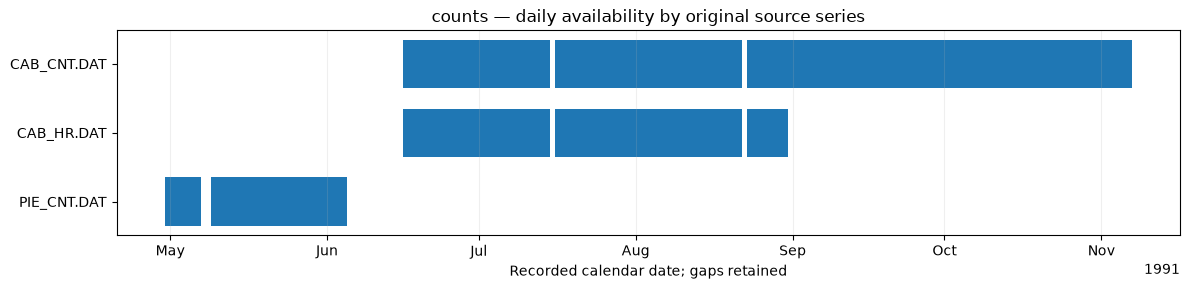

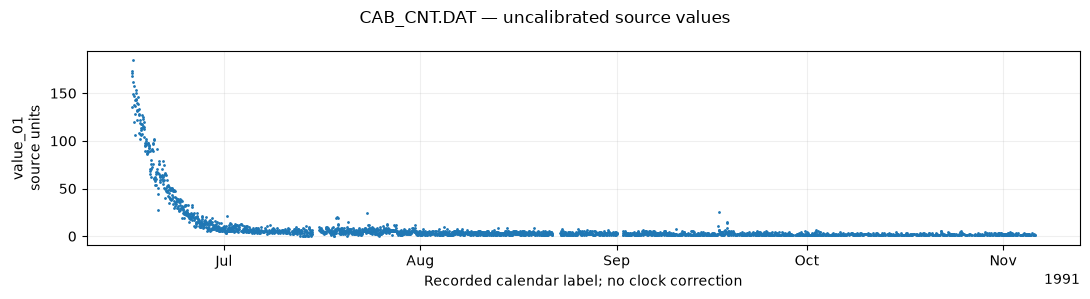

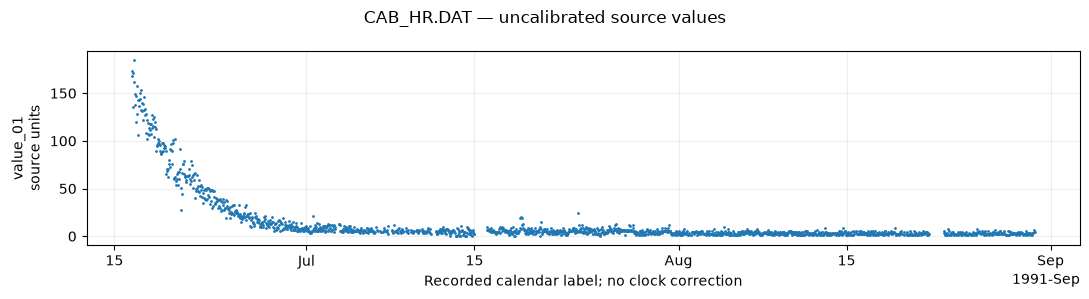

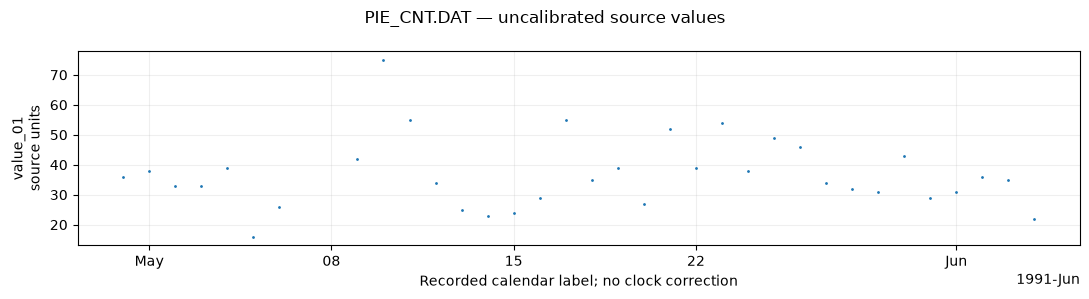

In [4]:
dataset=read_counts(product_source('counts','COUNTS'))
target=export_product(dataset,'counts',NOTES)
plot_product(dataset,target)


## Review before using in the manuscript

Check errors and duplicate timestamps, channel identities, units, missing flags and timing evidence. Independent computers and helicorders had separate clocks and drift. Agreement within one acquisition system does not demonstrate synchronization to another. These notebooks do not apply CVO/Philippines/GMT shifts, resample values, fill gaps, merge duplicate sources or assign waveform SEED identities.
